<a href="https://colab.research.google.com/github/darren0000001/all-activity/blob/main/Copy_of_agad_ML_Activity_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
accuracy_score,
                              confusion_matrix,
                              ConfusionMatrixDisplay,
                              roc_curve,
                              auc
)
from sklearn.preprocessing import label_binarize

In [ ]:
iris = load_iris()

In [ ]:
df = pd.DataFrame(
iris.data,
columns=iris.feature_names
)
df['species'] = iris.target_names[iris.target]
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
df = pd.DataFrame(
iris.data

Number of observation: 150
Number of features: 4


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


<function matplotlib.pyplot.show(close=None, block=None)>

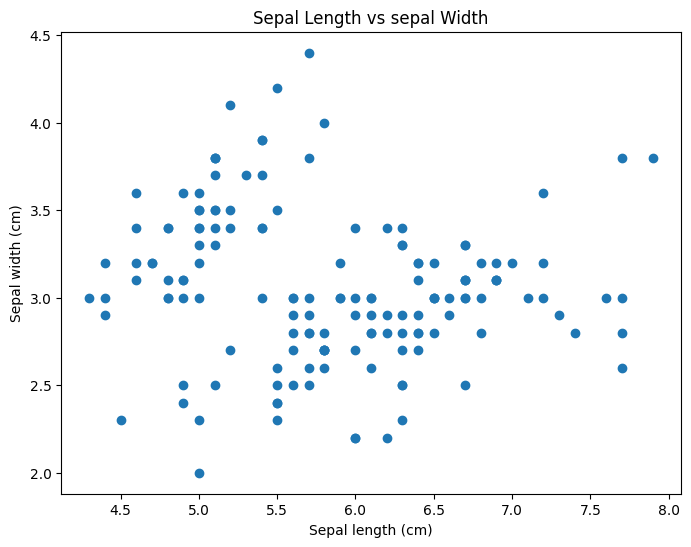

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(
    df["sepal length (cm)"],
    df["sepal width (cm)"]
)
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("Sepal Length vs sepal Width")

plt.show

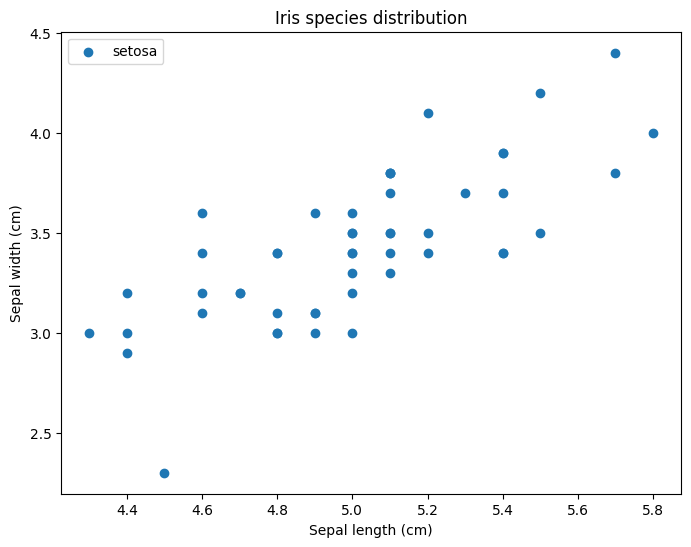

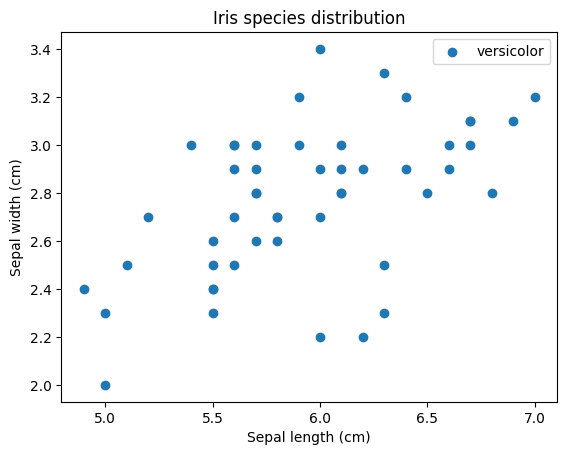

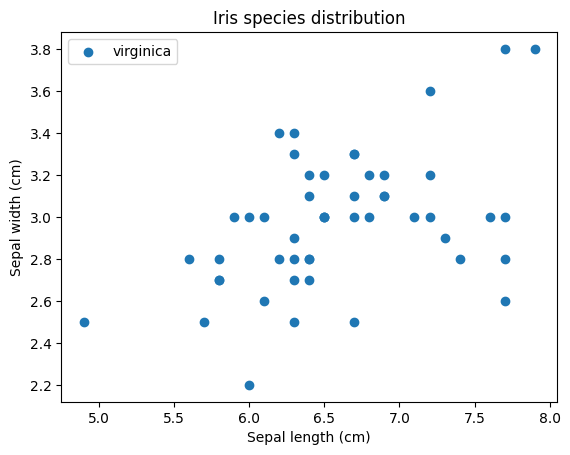

In [ ]:
plt.figure(figsize=(8,6))

for species in df["species"].unique():
  subset = df[df["species"]==species]

  plt.scatter(
      subset["sepal length (cm)"],
      subset["sepal width (cm)"],
      label = species
  )

  plt.xlabel("Sepal length (cm)")
  plt.ylabel("Sepal width (cm)")
  plt.title("Iris species distribution")
  plt.legend()

  plt.show()

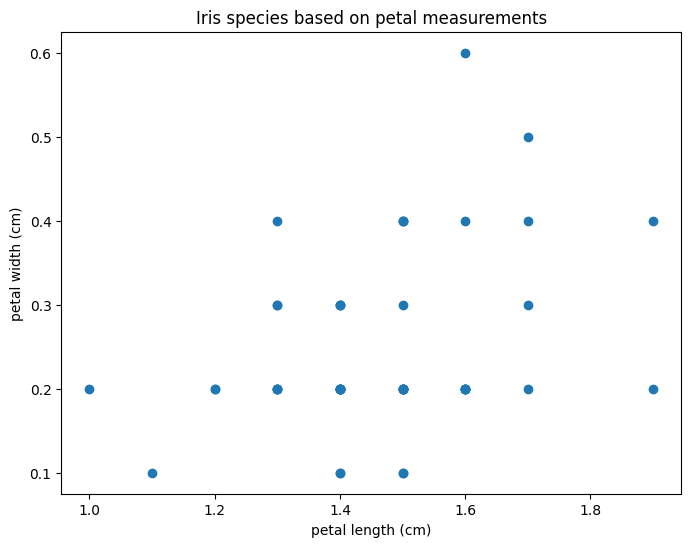

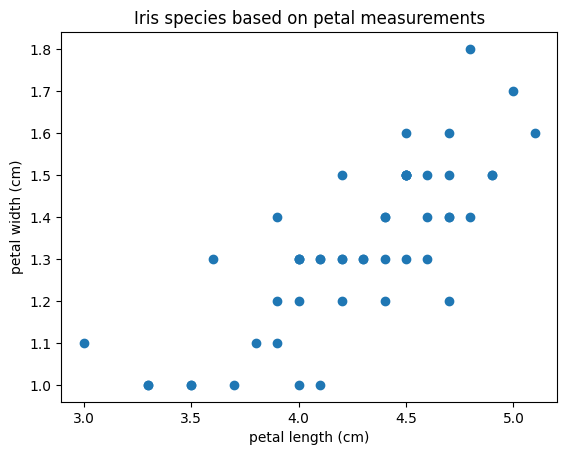

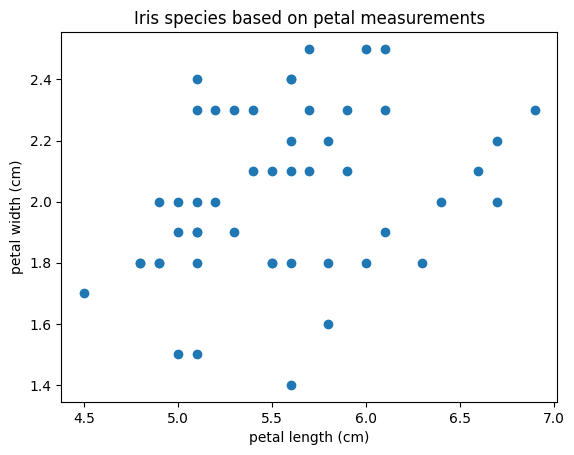

In [ ]:
plt.figure(figsize=(8,6))

for species in df["species"].unique():
  subset = df[df["species"]==species]

  plt.scatter(
      subset["petal length (cm)"],
      subset["petal width (cm)"],
      label = species
  )

  plt.xlabel("petal length (cm)")
  plt.ylabel("petal width (cm)")
  plt.title("Iris species based on petal measurements")
  plt.legend

  plt.show()

In [ ]:
x = iris.data
y = iris.target

In [ ]:
print("X Shape:", x.shape)
print("Y Shape:", y.shape)

X Shape: (150, 4)
Y Shape: (150,)


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
model=KNeighborsClassifier(n_neighbors=3)

In [ ]:
model.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
y_pred = model.predict(x_test)

In [ ]:
print("Actual: ")
print(y_test)

print("\nPredicted:")
print(y_pred)

Actual: 
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("n\Accuracy:", accuracy)

n\Accuracy: 1.0


<>:2: SyntaxWarning: invalid escape sequence '\A'
<>:2: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_996/923165707.py:2: SyntaxWarning: invalid escape sequence '\A'
  print("n\Accuracy:", accuracy)


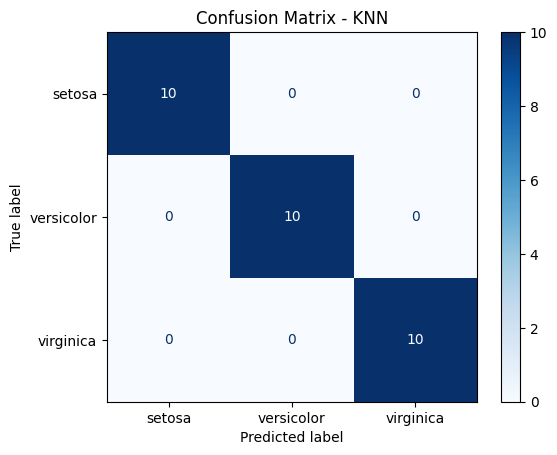

In [ ]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - KNN")
plt.show()

In [ ]:
y_test_bin = label_binarize(y_test,classes = [0, 1, 2])

In [ ]:
+y_score = model.predict_proba(X_test)

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (2874721296.py, line 1)

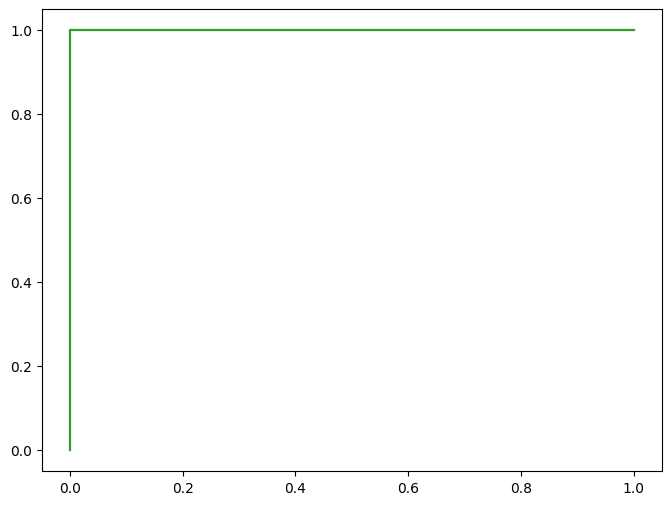

In [ ]:
plt.figure(figsize=(8, 6))

for i in range(3):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{iris.target_names[i]} (AUC = {roc_auc:.2f})"
    )

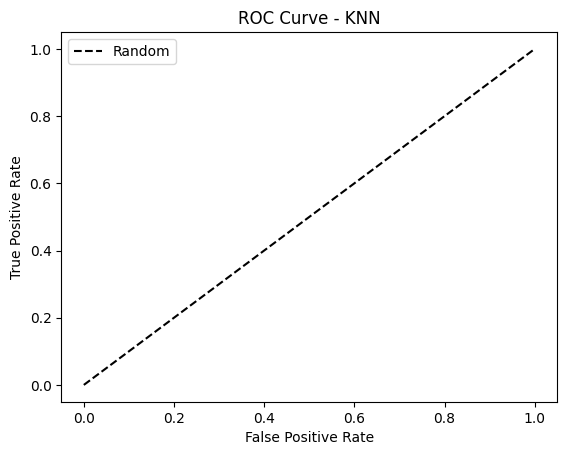

In [ ]:
plt.plot(
    [0 , 1],
     [0 , 1],
    "k--",
    label = "Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN")

plt.legend()
plt.show()

In [ ]:
new_flower=[[5.1, 3.5, 1.4, 0.2]]

In [ ]:
prediction = model.predict(new_flower)
print(
    "Predict Species: ",
    iris.target_names[prediction[0]]
)

Predict Species:  setosa
